# Nhóm 1: so sánh bốn cấu hình SAT

Nguồn: `results/data/group1_product_120s.csv`, gồm **113 đồ thị × 4 cấu hình = 452 lượt chạy**,
với giới hạn 120 giây/lượt. Phân tích dùng cả `hb_33` và `hb_80`.

| Nhãn trên hình | Cấu hình trong CSV |
| --- | --- |
| PW + Product / Repeated | Pairwise + Product + Repeated |
| PW + Product / Incremental | Pairwise + Product + Incremental |
| Order / Repeated | Order + Repeated |
| Order / Incremental | Order + Incremental |

Cột `cardinality` chứa tên đầy đủ của cấu hình. **Nghiệm hợp lệ** trong notebook là các dòng
có trạng thái `FEASIBLE` hoặc `OPTIMAL`. Các giá trị bandwidth trên dòng `ERROR`/`TIMEOUT`
không được dùng như nghiệm trả về của solver.

Chạy từ trên xuống dưới bằng kernel `.venv`. Mỗi hình được lưu dưới dạng PNG
ngay trong `results/visualization/png/`.


In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, PercentFormatter
from IPython.display import display

CONFIGURATIONS = [
    "Pairwise + Product + Repeated",
    "Pairwise + Product + Incremental",
    "Order + Repeated",
    "Order + Incremental",
]
CONFIG_LABELS = [
    "PW + Product\nRepeated",
    "PW + Product\nIncremental",
    "Order\nRepeated",
    "Order\nIncremental",
]
CONFIG_SHORT = dict(zip(CONFIGURATIONS, [label.replace("\n", " / ") for label in CONFIG_LABELS]))
CONFIG_COLORS = dict(zip(CONFIGURATIONS, ["#4C78A8", "#F58518", "#54A24B", "#E45756"]))
CONFIG_MARKERS = dict(zip(CONFIGURATIONS, ["o", "s", "^", "D"]))
STATUSES = ["OPTIMAL", "FEASIBLE", "TIMEOUT", "ERROR"]
VALID_STATUSES = {"OPTIMAL", "FEASIBLE"}
STATUS_COLORS = dict(zip(STATUSES, ["#2E8B57", "#4C78A8", "#ECA82C", "#C44E52"]))
DATA_GROUPS = ["hb_33", "hb_80"]
GROUP_COLORS = {"hb_33": "#4575B4", "hb_80": "#D98932"}
GROUP_MARKERS = {"hb_33": "o", "hb_80": "^"}

root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "results/data/group1_product_120s.csv").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Không tìm thấy results/data/group1_product_120s.csv")
csv_path = root / "results/data/group1_product_120s.csv"
figure_dir = root / "results/visualization/png"
figure_dir.mkdir(parents=True, exist_ok=True)

plt.rcdefaults()
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "figure.titlesize": 15,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
})
saved_figures = []

def save_figure(fig, stem):
    path = figure_dir / f"{stem}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    saved_figures.append(path)

print("Nguồn dữ liệu:", csv_path)


Nguồn dữ liệu: d:\EXP\year-3-semester-1\Contemporary-issues-in-computer-science\Bandwidth-Minimization-Problem\results\data\group1_product_120s.csv


## Đọc và kiểm tra dữ liệu

Mỗi đồ thị phải có đúng một dòng cho mỗi cấu hình. Kiểm tra cả tập đồ thị trong
`data/hb_33/`, `data/hb_80/`, số liệu đồ thị và trạng thái trước khi so sánh.
Các tập dùng cho từng hình được tạo một lần từ cùng bảng dữ liệu dưới đây.


In [14]:
group1 = pd.read_csv(csv_path)
required = {
    "instance", "n", "m", "cardinality", "status", "bandwidth",
    "total_time", "build_time", "solve_time", "num_vars", "num_clauses", "sat_calls",
}
if not required.issubset(group1.columns):
    raise ValueError(f"CSV thiếu cột: {required - set(group1.columns)}")
if group1[list(required)].isna().any().any():
    raise ValueError("CSV có ô trống trong các cột cần phân tích")
if set(group1["cardinality"]) != set(CONFIGURATIONS):
    raise ValueError("CSV không có đúng bốn cấu hình Nhóm 1")
if not group1["status"].isin(STATUSES).all():
    raise ValueError("CSV có trạng thái không hợp lệ")
if group1.duplicated(["instance", "cardinality"]).any():
    raise ValueError("Có cặp đồ thị/cấu hình bị lặp")

numeric_columns = sorted(required - {"instance", "cardinality", "status"})
for column in numeric_columns:
    group1[column] = pd.to_numeric(group1[column], errors="raise")
if not np.isfinite(group1[numeric_columns].to_numpy(dtype=float)).all():
    raise ValueError("CSV có số liệu không hữu hạn")
if (group1[numeric_columns] < 0).any().any() or (group1["n"] < 1).any():
    raise ValueError("Số liệu phải không âm và số đỉnh phải dương")
if (group1.groupby("instance")[["n", "m"]].nunique() != 1).any().any():
    raise ValueError("Số đỉnh/cạnh không nhất quán giữa các cấu hình")

instance_group = {}
for data_group in DATA_GROUPS:
    paths = sorted((root / "data" / data_group).glob("*.mtx.rnd"))
    if not paths:
        raise ValueError(f"Không tìm thấy đồ thị trong data/{data_group}")
    for path in paths:
        name = path.name.removesuffix(".mtx.rnd")
        if name in instance_group:
            raise ValueError(f"Tên đồ thị bị lặp giữa hai nhóm: {name}")
        instance_group[name] = data_group

instance_count = len(instance_group)
if set(group1["instance"]) != set(instance_group):
    raise ValueError("Tập đồ thị trong CSV không khớp hb_33 và hb_80")
if len(group1) != instance_count * len(CONFIGURATIONS):
    raise ValueError("CSV chưa có đủ lượt chạy cho các đồ thị/cấu hình")
group1["data_group"] = group1["instance"].map(instance_group)
valid_mask = group1["status"].isin(VALID_STATUSES)
valid_records = group1.loc[valid_mask].copy()
if ((valid_records["bandwidth"] < 0) | (valid_records["bandwidth"] >= valid_records["n"])).any():
    raise ValueError("Nghiệm hợp lệ có bandwidth ngoài miền 0..n-1")

status_counts = pd.crosstab(group1["cardinality"], group1["status"]).reindex(
    index=CONFIGURATIONS, columns=STATUSES, fill_value=0,
)
valid_bandwidth = group1.assign(
    valid_bandwidth=group1["bandwidth"].where(valid_mask)
).pivot(index="instance", columns="cardinality", values="valid_bandwidth").reindex(
    index=sorted(instance_group), columns=CONFIGURATIONS,
)
common_instances = valid_bandwidth.index[valid_bandwidth.notna().all(axis=1)]
common_count = len(common_instances)
if common_count == 0:
    raise ValueError("Không có đồ thị nào có nghiệm hợp lệ ở cả bốn cấu hình")
time_records = valid_records[valid_records["instance"].isin(common_instances)].copy()
cnf_records = valid_records[
    (valid_records["num_vars"] > 0) & (valid_records["num_clauses"] > 0)
].copy()

print(f"Đã kiểm tra: {len(group1)} dòng, {instance_count} đồ thị, {len(CONFIGURATIONS)} cấu hình")
print(f"Lượt có nghiệm hợp lệ: {len(valid_records)}/{len(group1)}")
print(f"Tập so sánh thời gian chung: {common_count} đồ thị")
print(f"Lượt dùng để vẽ kích thước CNF: {len(cnf_records)}/{len(group1)}")


Đã kiểm tra: 452 dòng, 113 đồ thị, 4 cấu hình
Lượt có nghiệm hợp lệ: 315/452
Tập so sánh thời gian chung: 43 đồ thị
Lượt dùng để vẽ kích thước CNF: 315/452


## Hình 1: trạng thái kết quả trên toàn bộ tập dữ liệu

Mỗi cột là một cấu hình. Chiều cao các phần cho biết số lượt `OPTIMAL`, `FEASIBLE`,
`TIMEOUT`, `ERROR`. Ô đầu dùng toàn bộ đồ thị; hai ô còn lại giúp nhận biết sự khác nhau
giữa `hb_33` và `hb_80`. `FEASIBLE` là đã có nghiệm nhưng chưa chứng minh tối ưu.


status,OPTIMAL,FEASIBLE,TIMEOUT,ERROR
Cấu hình,,,,
PW + Product / Repeated,4,109,0,0
PW + Product / Incremental,6,107,0,0
Order / Repeated,3,43,0,67
Order / Incremental,3,40,0,70


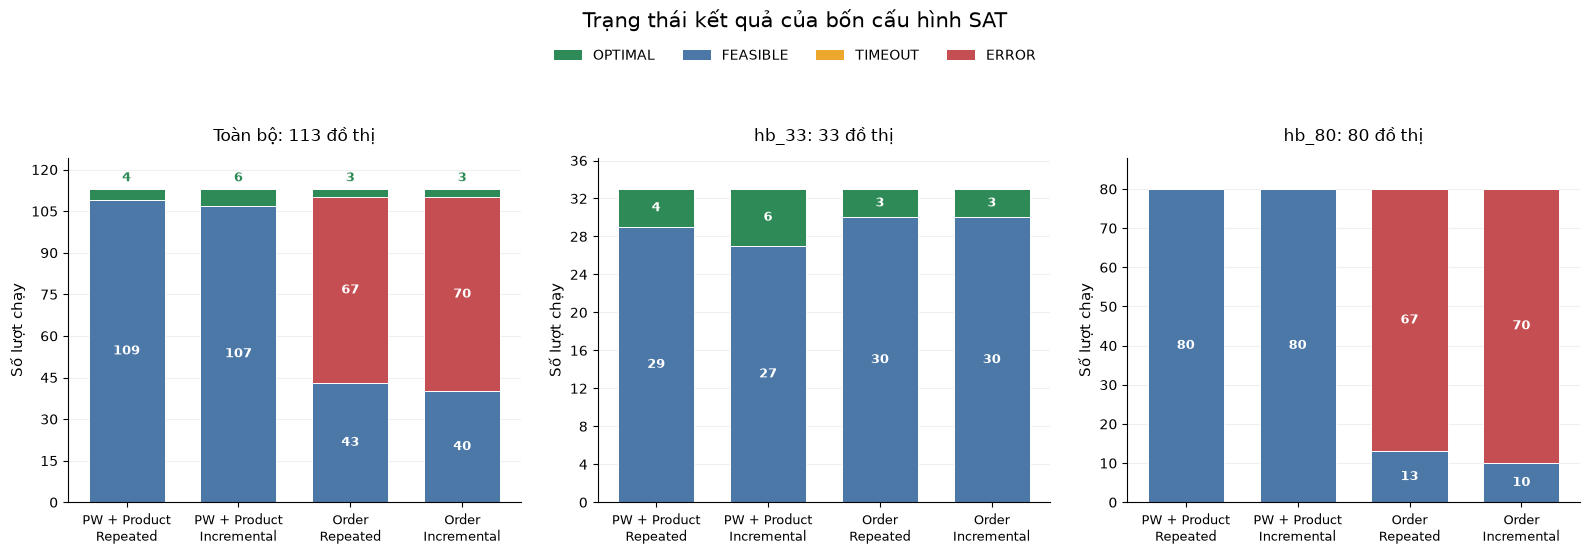

In [15]:
display(status_counts.rename(index=CONFIG_SHORT).rename_axis("Cấu hình"))

scopes = [("Toàn bộ", group1)] + [
    (data_group, group1[group1["data_group"].eq(data_group)])
    for data_group in DATA_GROUPS
]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.4))
for ax, (scope_name, records) in zip(axes, scopes):
    counts = pd.crosstab(records["cardinality"], records["status"]).reindex(
        index=CONFIGURATIONS, columns=STATUSES, fill_value=0,
    )
    n_graphs = records["instance"].nunique()
    positions = np.arange(len(CONFIGURATIONS))
    bottom = np.zeros(len(CONFIGURATIONS), dtype=int)
    for status in ["FEASIBLE", "TIMEOUT", "ERROR", "OPTIMAL"]:
        heights = counts[status].to_numpy()
        ax.bar(positions, heights, bottom=bottom, color=STATUS_COLORS[status],
               edgecolor="white", linewidth=0.7, width=0.68)
        for x, height, base in zip(positions, heights, bottom):
            if height:
                if height < n_graphs * 0.055:
                    ax.text(x, base + height + n_graphs * 0.015, str(int(height)),
                            ha="center", va="bottom", color=STATUS_COLORS[status],
                            fontsize=9, fontweight="bold")
                else:
                    ax.text(x, base + height / 2, str(int(height)), ha="center", va="center",
                            color="white" if status != "TIMEOUT" else "#222222", fontsize=9,
                            fontweight="bold")
        bottom += heights
    ax.set_xticks(positions, CONFIG_LABELS, fontsize=9)
    ax.set_title(f"{scope_name}: {n_graphs} đồ thị", pad=12)
    ax.set_ylim(0, n_graphs * 1.10)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="y", alpha=0.2)
    ax.set_ylabel("Số lượt chạy")
fig.suptitle("Trạng thái kết quả của bốn cấu hình SAT", y=1.02)
fig.legend([Patch(facecolor=STATUS_COLORS[s]) for s in STATUSES], STATUSES,
           loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.9), w_pad=2)
save_figure(fig, "group1_01_status")
plt.show()


## Hình 2: performance profile về chất lượng nghiệm

Với đồ thị `i` và cấu hình `a`, tính **r(i, a) = bandwidth(i, a) / bandwidth tốt nhất
quan sát được trên cùng đồ thị**, chỉ dùng nghiệm `FEASIBLE`/`OPTIMAL` để xác định mẫu số.
Đây là mốc tốt nhất trong thí nghiệm, không mặc nhiên là tối ưu đã được chứng minh.

Trục X là ngưỡng tỷ lệ `r`; trục Y là phần trăm **trên toàn bộ đồ thị**, không chia riêng
cho số lượt thành công của mỗi cấu hình. Lượt `ERROR`/`TIMEOUT` được coi là không đạt
mọi ngưỡng hữu hạn. Đường cao hơn, đi lên sớm hơn cho thấy độ bao phủ và chất lượng tốt hơn.
Vì vậy, đường Order có thể dừng dưới 100% do các lượt lỗi.


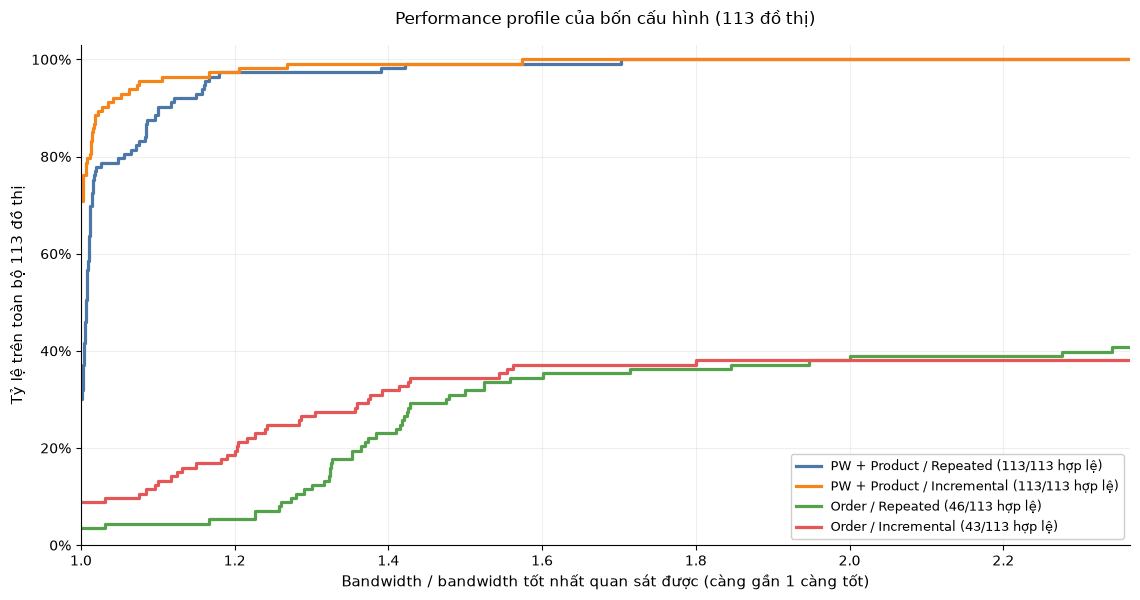

,Có nghiệm hợp lệ,Đạt bandwidth tốt nhất (kể cả hòa),Độ bao phủ tối đa (%)
Cấu hình,,,
PW + Product / Repeated,113,34,100.00
PW + Product / Incremental,113,80,100.00
Order / Repeated,46,4,40.71
Order / Incremental,43,10,38.05


In [16]:
best_observed = valid_bandwidth.min(axis=1)
if best_observed.isna().any():
    raise ValueError("Có đồ thị chưa có nghiệm hợp lệ để xác định mốc so sánh")
quality_ratios = valid_bandwidth.div(best_observed.replace(0, np.nan), axis=0)
zero_best = best_observed.eq(0)
if zero_best.any():
    quality_ratios.loc[zero_best] = np.where(
        valid_bandwidth.loc[zero_best].eq(0), 1.0, np.inf,
    )
quality_ratios = quality_ratios.fillna(np.inf)
finite_values = quality_ratios.to_numpy()[np.isfinite(quality_ratios.to_numpy())]
profile_xmax = max(1.05, float(finite_values.max()) * 1.01)

fig, ax = plt.subplots(figsize=(11.5, 6.1))
profile_rows = []
for config in CONFIGURATIONS:
    ratios = quality_ratios[config].to_numpy()
    finite = np.sort(ratios[np.isfinite(ratios)])
    thresholds = np.unique(np.r_[1.0, finite, profile_xmax])
    coverage = (finite[:, None] <= thresholds[None, :]).sum(axis=0) / instance_count * 100
    ax.step(thresholds, coverage, where="post", color=CONFIG_COLORS[config], linewidth=2.3,
            label=f"{CONFIG_SHORT[config]} ({len(finite)}/{instance_count} hợp lệ)")
    profile_rows.append({
        "Cấu hình": CONFIG_SHORT[config],
        "Có nghiệm hợp lệ": len(finite),
        "Đạt bandwidth tốt nhất (kể cả hòa)": int(np.isclose(ratios, 1.0).sum()),
        "Độ bao phủ tối đa (%)": round(len(finite) / instance_count * 100, 2),
    })
profile_summary = pd.DataFrame(profile_rows).set_index("Cấu hình")
ax.set_xlim(1.0, profile_xmax)
ax.set_ylim(0, 103)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set_xlabel("Bandwidth / bandwidth tốt nhất quan sát được (càng gần 1 càng tốt)")
ax.set_ylabel(f"Tỷ lệ trên toàn bộ {instance_count} đồ thị")
ax.set_title(f"Performance profile của bốn cấu hình ({instance_count} đồ thị)", pad=15)
ax.grid(alpha=0.2)
ax.legend(loc="lower right", framealpha=0.95, fontsize=9)
fig.tight_layout()
save_figure(fig, "group1_02_quality_profile")
plt.show()
display(profile_summary)


## Hình 3: Repeated so với Incremental trên cùng đồ thị

Mỗi điểm là một đồ thị có nghiệm hợp lệ ở **cả hai cấu hình của cặp đang so sánh**.
Trục X là bandwidth của Repeated, trục Y là bandwidth của Incremental.
Điểm dưới đường `y = x` nghĩa là Incremental cho bandwidth nhỏ hơn; điểm trên đường nghĩa
là Repeated tốt hơn. Các lượt lỗi được loại theo cặp và số đồ thị được ghi ngay trên từng ô.


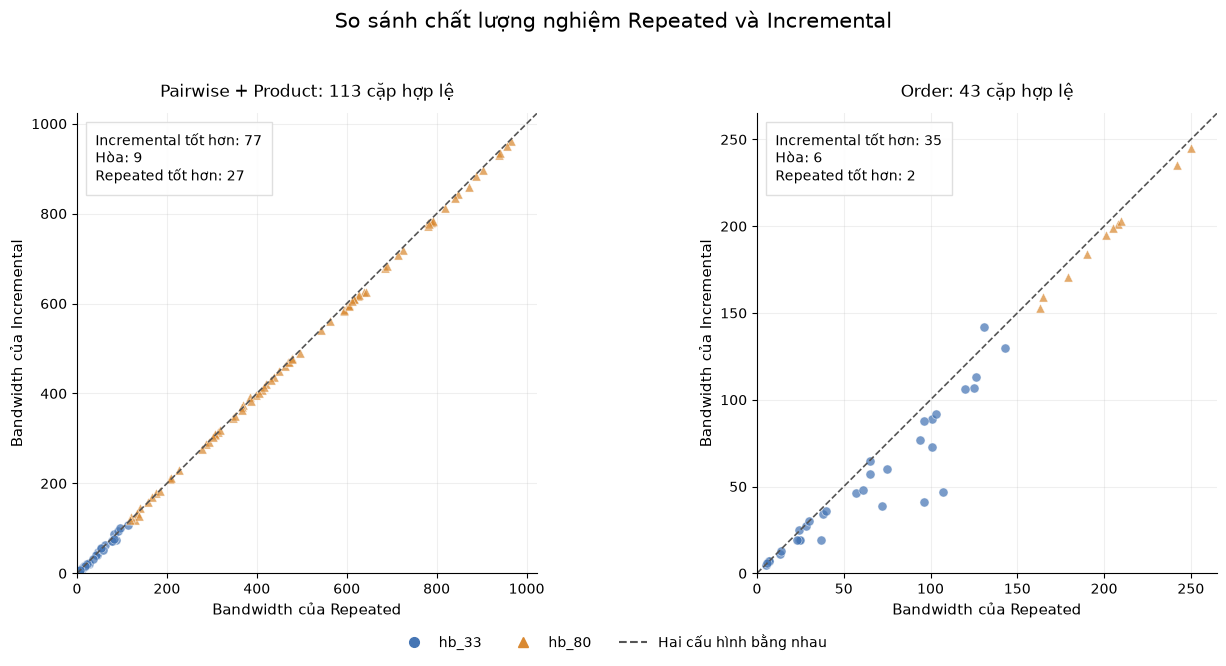

,Số đồ thị,Incremental tốt hơn,Hòa,Repeated tốt hơn
Cặp cấu hình,,,,
Pairwise + Product,113,77,9,27
Order,43,35,6,2


In [17]:
pairs = [
    ("Pairwise + Product", CONFIGURATIONS[0], CONFIGURATIONS[1]),
    ("Order", CONFIGURATIONS[2], CONFIGURATIONS[3]),
]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.5))
pair_rows = []
for ax, (pair_name, repeated, incremental) in zip(axes, pairs):
    paired = valid_bandwidth[[repeated, incremental]].dropna()
    if paired.empty:
        raise ValueError(f"Không có cặp nghiệm hợp lệ cho {pair_name}")
    x, y = paired[repeated], paired[incremental]
    for data_group in DATA_GROUPS:
        names = [name for name in paired.index if instance_group[name] == data_group]
        ax.scatter(x.loc[names], y.loc[names], s=43, color=GROUP_COLORS[data_group],
                   marker=GROUP_MARKERS[data_group], alpha=0.72,
                   edgecolors="white", linewidths=0.45)
    lower = max(0.0, float(paired.min().min()) - float(paired.max().max()) * 0.035)
    upper = float(paired.max().max()) * 1.06
    ax.plot([lower, upper], [lower, upper], linestyle="--", color="#555555", linewidth=1.2)
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")
    better = int(y.lt(x).sum())
    tied = int(y.eq(x).sum())
    worse = int(y.gt(x).sum())
    ax.text(0.04, 0.96,
            f"Incremental tốt hơn: {better}\nHòa: {tied}\nRepeated tốt hơn: {worse}",
            transform=ax.transAxes, ha="left", va="top", fontsize=10,
            bbox={"facecolor": "white", "edgecolor": "#DDDDDD", "alpha": 0.93, "pad": 7})
    ax.set_title(f"{pair_name}: {len(paired)} cặp hợp lệ", pad=12)
    ax.set_xlabel("Bandwidth của Repeated")
    ax.set_ylabel("Bandwidth của Incremental")
    ax.grid(alpha=0.2)
    pair_rows.append({"Cặp cấu hình": pair_name, "Số đồ thị": len(paired),
                      "Incremental tốt hơn": better, "Hòa": tied, "Repeated tốt hơn": worse})
pair_summary = pd.DataFrame(pair_rows).set_index("Cặp cấu hình")
handles = [Line2D([], [], marker=GROUP_MARKERS[g], linestyle="", color=GROUP_COLORS[g],
                  markersize=7, label=g) for g in DATA_GROUPS]
handles.append(Line2D([], [], color="#555555", linestyle="--", label="Hai cấu hình bằng nhau"))
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.005), ncol=3,
           frameon=False)
fig.suptitle("So sánh chất lượng nghiệm Repeated và Incremental", y=1.01)
fig.tight_layout(rect=(0, 0.07, 1, 0.96), w_pad=3)
save_figure(fig, "group1_03_repeated_vs_incremental")
plt.show()
display(pair_summary)
